In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r'C:\Users\boomt\Downloads\Advertising.csv')
df = df.drop(columns='Unnamed: 0')   # คอลัมน์นี้เป็นแค่เลขลำดับ
print('จำนวนแถว, คอลัมน์ =', df.shape)
df.head()


จำนวนแถว, คอลัมน์ = (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [6]:
print('ค่าสูญหายในแต่ละคอลัมน์')  
print(df.isnull().sum())  
print() 
print('จำนวนแถวซ้ำ =', df.duplicated().sum()) 

ค่าสูญหายในแต่ละคอลัมน์
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

จำนวนแถวซ้ำ = 0


In [7]:
import logging 
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # แสดงเฉพาะ error ร้ายแรง จึงไม่มีคำเตือน "font not found" ขึ้นรก

plt.rcParams['font.family'] = ['TH Sarabun New', 'Tahoma']  
plt.rcParams['font.size'] = 16  
plt.rcParams['axes.unicode_minus'] = False  

In [8]:
pd.DataFrame({ 
    'ค่าเฉลี่ย': df.mean(), 
    'ส.บ.ม. (ddof=1)': df.std(ddof=1),  # ส่วนเบี่ยงเบนมาตรฐาน
    'ต่ำสุด': df.min(),  
    'มัธยฐาน': df.median(),  
    'สูงสุด': df.max()  
}).round(2)


,ค่าเฉลี่ย,ส.บ.ม. (ddof=1),ต่ำสุด,มัธยฐาน,สูงสุด
TV,147.04,85.85,0.7,149.75,296.4
Radio,23.26,14.85,0.0,22.90,49.6
Newspaper,30.55,21.78,0.3,25.75,114.0
Sales,14.02,5.22,1.6,12.90,27.0


In [9]:
rows = []  # สร้างไว้เก็บผลของแต่ละตัวแปร
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr 
    n = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, n])

outlier_table = pd.DataFrame(rows, columns=['ตัวแปร', 'Q1', 'Q3', 'IQR', 'ขอบล่าง', 'ขอบบน', 'จำนวนค่าผิดปกติ']).round(2)  # แปลงลิสต์เป็นตาราง
outlier_table

,ตัวแปร,Q1,Q3,IQR,ขอบล่าง,ขอบบน,จำนวนค่าผิดปกติ
0,TV,74.38,218.82,144.45,-142.30,435.50,0
1,Radio,9.98,36.52,26.55,-29.85,76.35,0
2,Newspaper,12.75,45.10,32.35,-35.78,93.62,2
3,Sales,10.38,17.40,7.02,-0.16,27.94,0


In [10]:
q1 = df['Newspaper'].quantile(0.25)
q3 = df['Newspaper'].quantile(0.75) 
iqr = q3 - q1 
df[(df['Newspaper'] < q1 - 1.5*iqr) | (df['Newspaper'] > q3 + 1.5*iqr)]  # กรองเฉพาะแถวที่ Newspaper ผิดปกติ มาแสดง

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


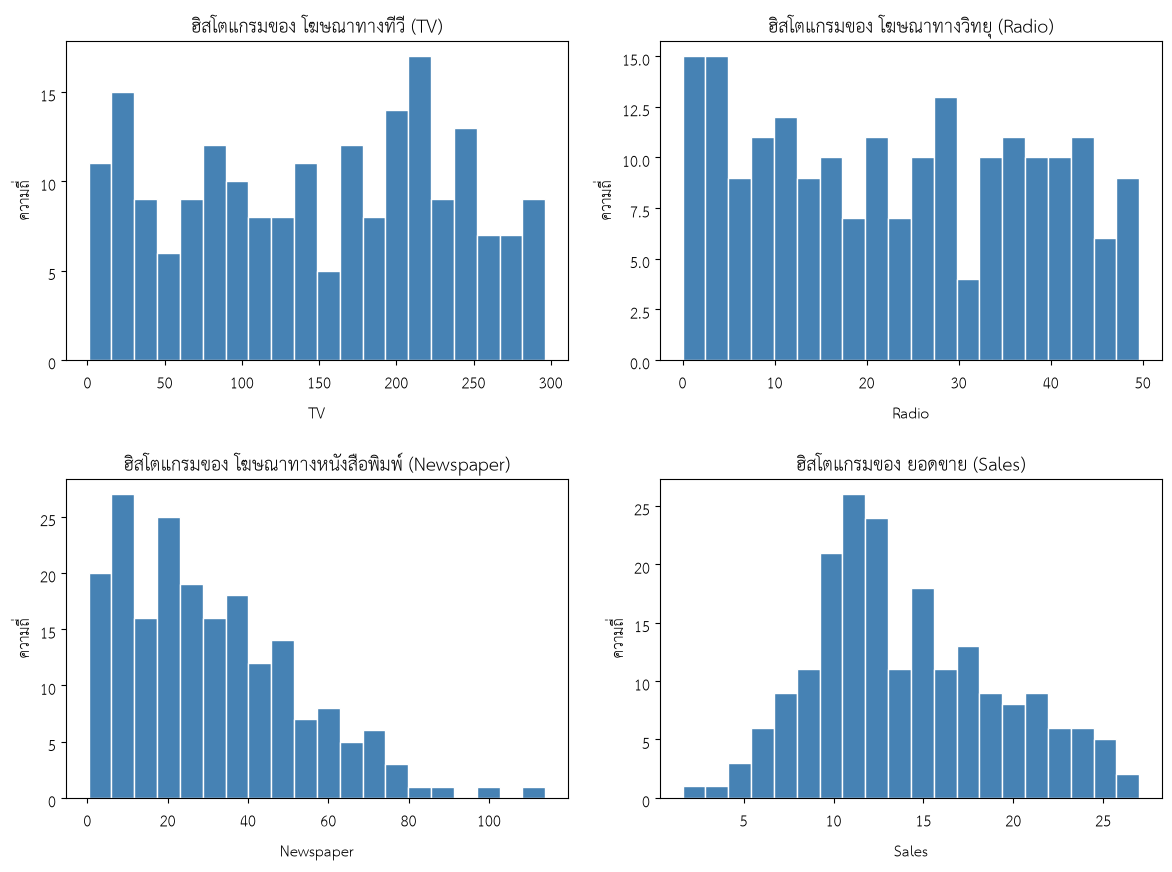

In [11]:
names = {'TV': 'โฆษณาทางทีวี (TV)', 'Radio': 'โฆษณาทางวิทยุ (Radio)', 'Newspaper': 'โฆษณาทางหนังสือพิมพ์ (Newspaper)', 'Sales': 'ยอดขาย (Sales)'}  

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flatten(), df.columns) :
    ax.hist(df[col], bins=20, color='steelblue', edgecolor='white') 
    ax.set_title('ฮิสโตแกรมของ ' + names[col])
    ax.set_xlabel(col)  
    ax.set_ylabel('ความถี่') 
 
plt.tight_layout()
plt.show()

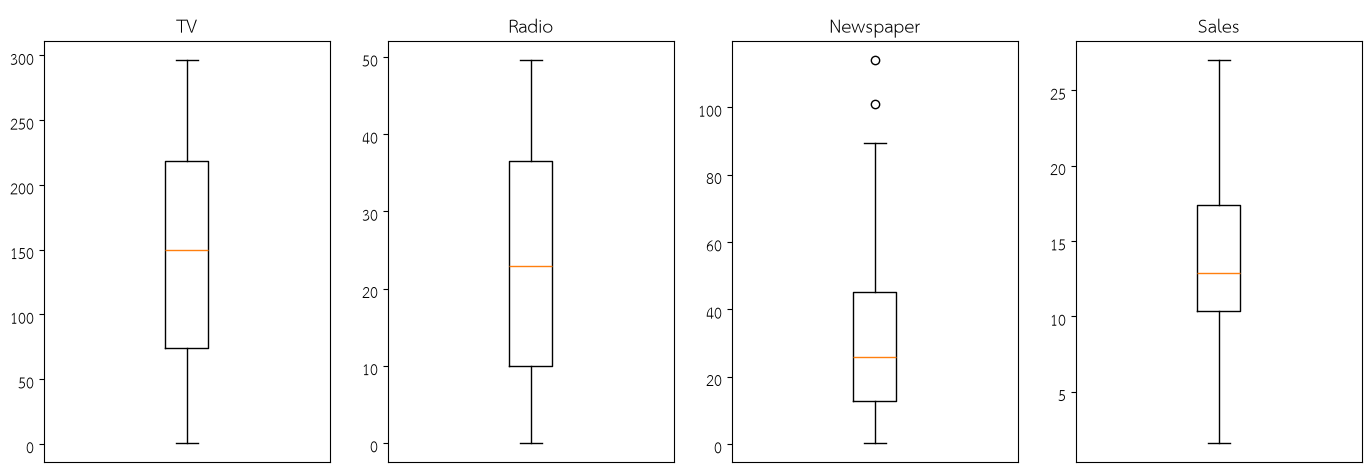

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, col in zip(axes, df.columns):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

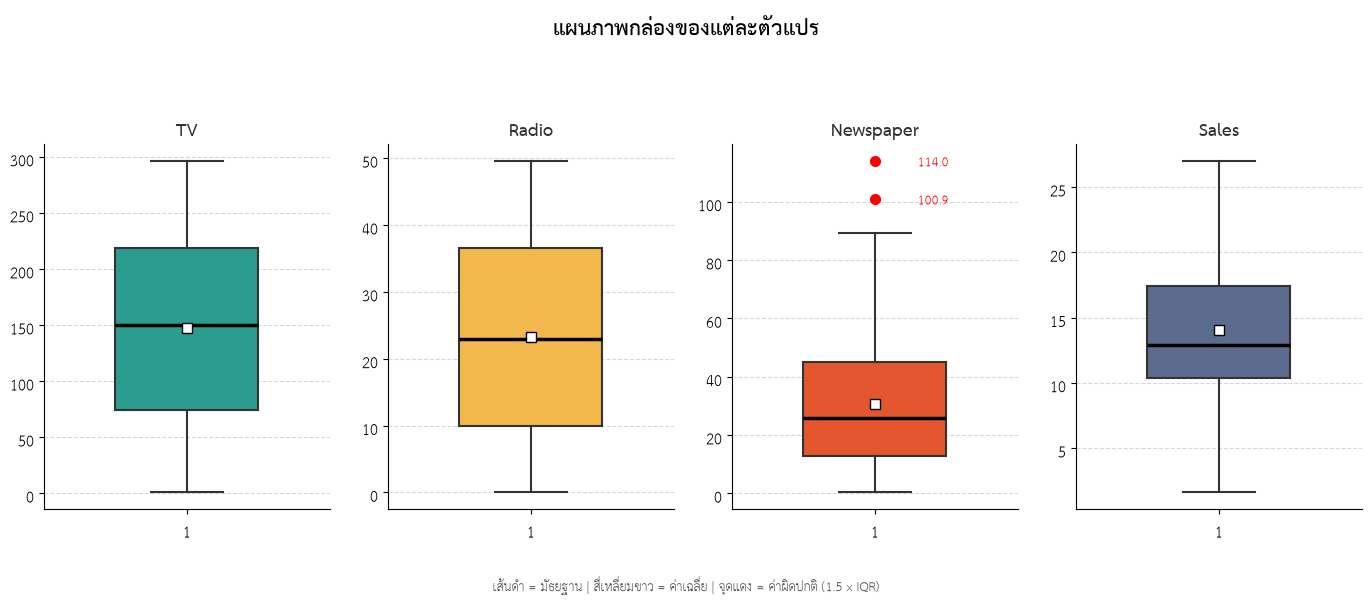

In [20]:
colors = ['#2A9D8F', '#F2B84B', '#E4572E', '#5B6C8F'] 

fig, axes = plt.subplots(1, 4, figsize=(14, 6)) 
for ax, col, color in zip(axes, df.columns, colors): 
    ax.boxplot(df[col], patch_artist=True, widths=0.5, showmeans=True,  
               boxprops=dict(facecolor=color, edgecolor='#333333', linewidth=1.5), 
               medianprops=dict(color='black', linewidth=2.5),
               meanprops=dict(marker='s', markerfacecolor='white', markeredgecolor='black', markersize=7),  
               whiskerprops=dict(color='#333333', linewidth=1.5),  
               capprops=dict(color='#333333', linewidth=1.5), 
               flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red', markersize=7)) 
    
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75) 
    iqr = q3 - q1  
    outs = df[col][(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)] 
    for v in outs: 
        ax.annotate(str(v), xy=(1, v), xytext=(1.15, v), va='center', color='red', fontsize=13)
    ax.set_title(col, fontsize=18, fontweight='bold', color='#333333')  
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)  
    ax.set_axisbelow(True) 
    ax.spines['top'].set_visible(False)  
    ax.spines['right'].set_visible(False)  

fig.suptitle('แผนภาพกล่องของแต่ละตัวแปร', fontsize=22, fontweight='bold')  
fig.text(0.5, 0.01, 'เส้นดำ = มัธยฐาน | สี่เหลี่ยมขาว = ค่าเฉลี่ย | จุดแดง = ค่าผิดปกติ (1.5 x IQR)', ha='center', fontsize=14, color='#555555')  
plt.tight_layout(rect=[0, 0.05, 1, 0.94]) 
plt.show()  

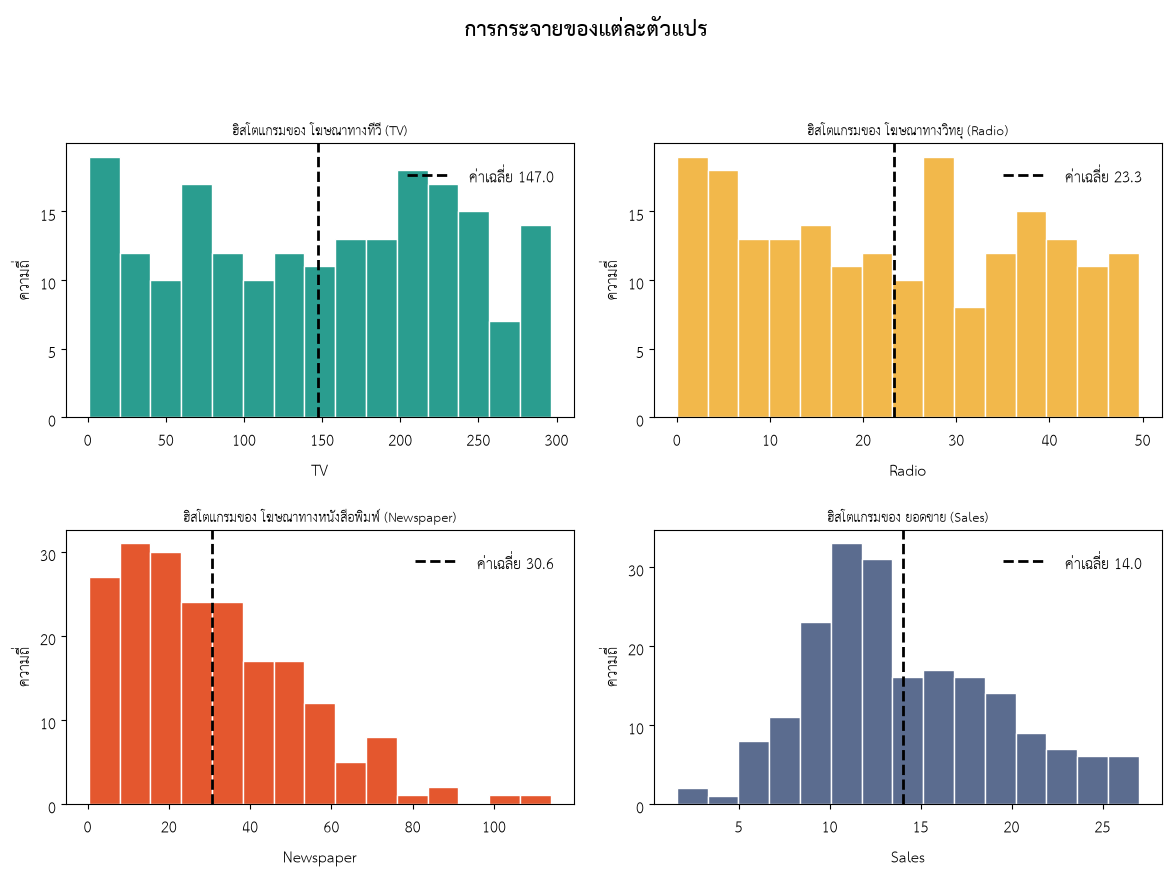

In [ ]:
colors = {'TV': '#2A9D8F', 'Radio': '#F2B84B', 'Newspaper': '#E4572E', 'Sales': '#5B6C8F'}
names = {'TV': 'โฆษณาทางทีวี (TV)', 'Radio': 'โฆษณาทางวิทยุ (Radio)',
         'Newspaper': 'โฆษณาทางหนังสือพิมพ์ (Newspaper)', 'Sales': 'ยอดขาย (Sales)'}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flatten(), df.columns):
    ax.hist(df[col], bins=15, color=colors[col], edgecolor='white')
    ax.axvline(df[col].mean(), color='black', linestyle='--', linewidth=2, label='ค่าเฉลี่ย ' + str(round(df[col].mean(), 1)))
    ax.set_title('ฮิสโตแกรมของ ' + names[col], fontsize=14)
    ax.set_xlabel(col)
    ax.set_ylabel('ความถี่')
    ax.legend(frameon=False)
fig.suptitle('การกระจายของแต่ละตัวแปร', fontsize=22, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

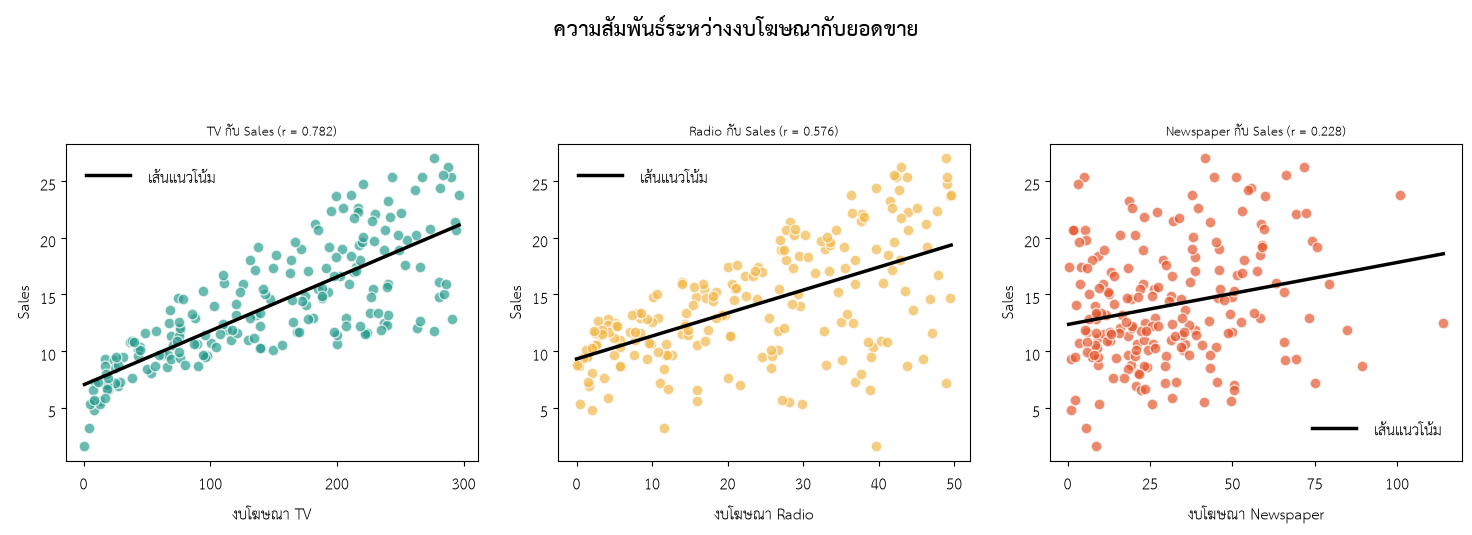

,TV,Radio,Newspaper,Sales
TV,1.000,0.055,0.057,0.782
Radio,0.055,1.000,0.354,0.576
Newspaper,0.057,0.354,1.000,0.228
Sales,0.782,0.576,0.228,1.000


In [22]:
colors = {'TV': '#2A9D8F', 'Radio': '#F2B84B', 'Newspaper': '#E4572E', 'Sales': '#5B6C8F'}

fig , axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    ax.scatter(df[col], df['Sales'], color=colors[col], alpha=0.7, edgecolor='white', s=60)
    m, b = np.polyfit(df[col], df['Sales'], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, m * xs + b, color='black', linewidth=2.5, label='เส้นแนวโน้ม')
    r = df[col].corr(df['Sales'])
    ax.set_title(col + ' กับ Sales (r = ' + str(round(r, 3)) + ')', fontsize=14)
    ax.set_xlabel('งบโฆษณา ' + col)
    ax.set_ylabel('Sales')
    ax.legend(frameon=False)
fig.suptitle('ความสัมพันธ์ระหว่างงบโฆษณากับยอดขาย', fontsize=22, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
corr = df.corr().round(3)
corr

In [40]:
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import make_pipeline  
from sklearn.preprocessing import PolynomialFeatures, StandardScaler  
from sklearn.linear_model import LinearRegression  
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 

X = df[['TV', 'Radio', 'Newspaper']]  
y = df['Sales'] 

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0) 
lin = LinearRegression() 
lin.fit(X_tr, y_tr)
pred_tr = lin.predict(X_tr)  
pred_te = lin.predict(X_te) 

pd.DataFrame({  
    'ชุดข้อมูล': ['train', 'test'], 
    'R2': [r2_score(y_tr, pred_tr), r2_score(y_te, pred_te)],  
    'RMSE': [np.sqrt(mean_squared_error(y_tr, pred_tr)), np.sqrt(mean_squared_error(y_te, pred_te))],  
    'MAE': [mean_absolute_error(y_tr, pred_tr), mean_absolute_error(y_te, pred_te)] 
}).round(4)  



,ชุดข้อมูล,R2,RMSE,MAE
0,train,0.9067,1.5514,1.2132
1,test,0.8601,2.0981,1.3618


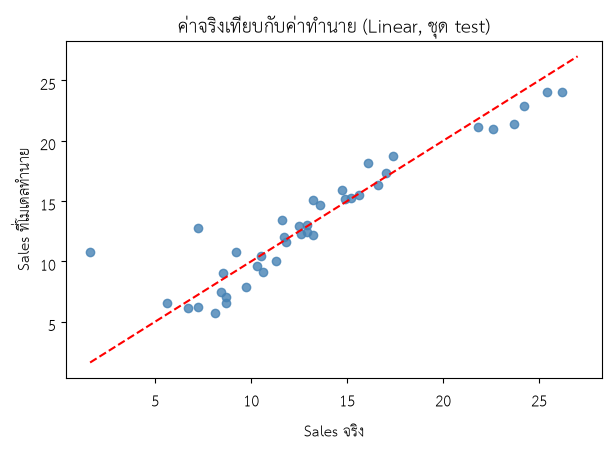

In [41]:
plt.scatter(y_te, pred_te, color='steelblue', alpha=0.8) 
lo, hi = y.min(), y.max()  
plt.plot([lo, hi], [lo, hi], color='red', linestyle='--')  
plt.title('ค่าจริงเทียบกับค่าทำนาย (Linear, ชุด test)') 
plt.xlabel('Sales จริง')  
plt.ylabel('Sales ที่โมเดลทำนาย')  
plt.tight_layout() 
plt.show() 